# 01 · Data exploration (before training)

What the model will see and what it must predict: input images, the original GT **boxes**,
the SAM-generated GT **instance masks**, and the GT **laser target points** from every method.

Prerequisite: `python scripts/prepare_data.py --dataset configs/datasets/cottonweeddet12.yaml`

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo root so config paths resolve the same way as in scripts/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.dpi"] = 110

In [2]:
from omegaconf import OmegaConf

from src.data.labels import polygon_to_mask, read_seg_labels, read_yolo_boxes
from src.targeting.points import POINT_METHODS, point_in_mask, target_point
from src.utils.io import load_json
from src.visualization import GT_COLOR, METHOD_COLORS, draw_instances, draw_target, load_rgb

DATASET_CONFIG = "configs/datasets/cottonweeddet12.yaml"
SPLIT = "train"      # split to sample images from
NUM_SAMPLES = 6
SEED = 0

ds = OmegaConf.load(DATASET_CONFIG)
raw_dir, prepared_dir = Path(ds.raw_dir), Path(ds.prepared_dir)
info = load_json(prepared_dir / "prepare_info.json")
class_names = info["class_names"]
print(f"{ds.name}: GT masks from {info['settings']['sam_model']}, SAM fallback boxes: {info['sam_fallback_boxes']}")

cottonweeddet12: GT masks from models/weights/sam2.1_b.pt, SAM fallback boxes: 0


## Split sizes and class distribution

,train,val,test
images,1554,478,359
instances,2255,718,540


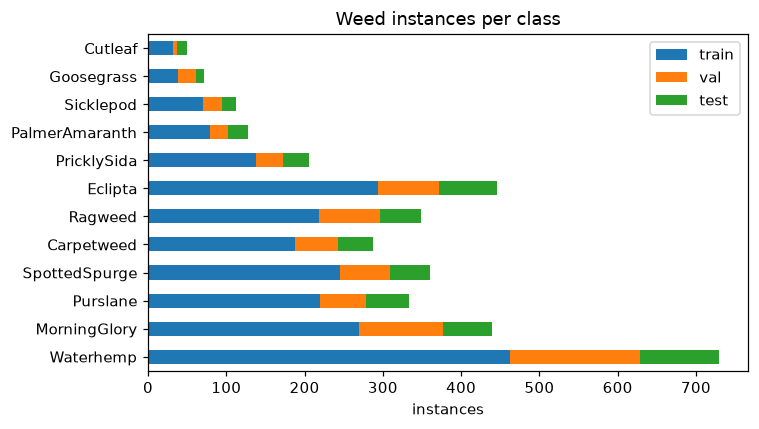

In [3]:
splits = pd.DataFrame({s: v["instances_per_class"] for s, v in info["splits"].items()})
display(pd.DataFrame({s: {"images": v["num_images"], "instances": v["num_instances"]} for s, v in info["splits"].items()}))
splits.plot(kind="barh", stacked=True, figsize=(7, 4), title="Weed instances per class")
plt.xlabel("instances"); plt.tight_layout(); plt.show()

## Instances per image and weed size
Mask area as a fraction of the image (the area of a normalized polygon equals that fraction directly).

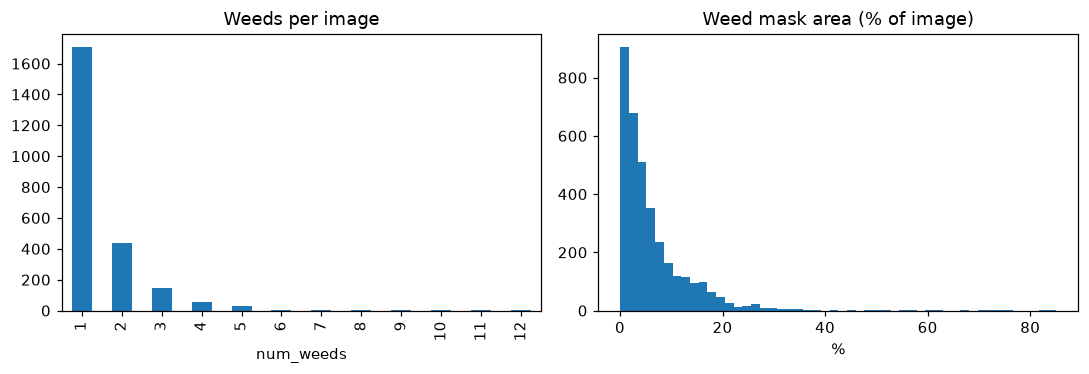

median weed area: 3.91% of image, images without weeds: 0


In [4]:
rows = []
for split in ("train", "val", "test"):
    for label_file in sorted((prepared_dir / "labels" / split).glob("*.txt")):
        instances = read_seg_labels(label_file)
        rows.append({"split": split, "image": label_file.stem, "num_weeds": len(instances),
                     "areas": [cv2.contourArea(inst.polygon) for inst in instances]})
per_image = pd.DataFrame(rows)
areas = np.concatenate([a for a in per_image["areas"] if a])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
per_image["num_weeds"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Weeds per image")
axes[1].hist(areas * 100, bins=50); axes[1].set_title("Weed mask area (% of image)"); axes[1].set_xlabel("%")
plt.tight_layout(); plt.show()
print(f"median weed area: {np.median(areas) * 100:.2f}% of image, images without weeds: {(per_image.num_weeds == 0).sum()}")

## Input → ground truth, sample images
Left: model input. Middle: original GT box (red) and the SAM mask derived from it (the training target).
Right: GT target point of every method (legend below).

point colors: {'distance_transform': (255, 215, 0), 'centroid': (0, 150, 255), 'skeleton': (255, 0, 255), 'box_center': (255, 255, 255)}


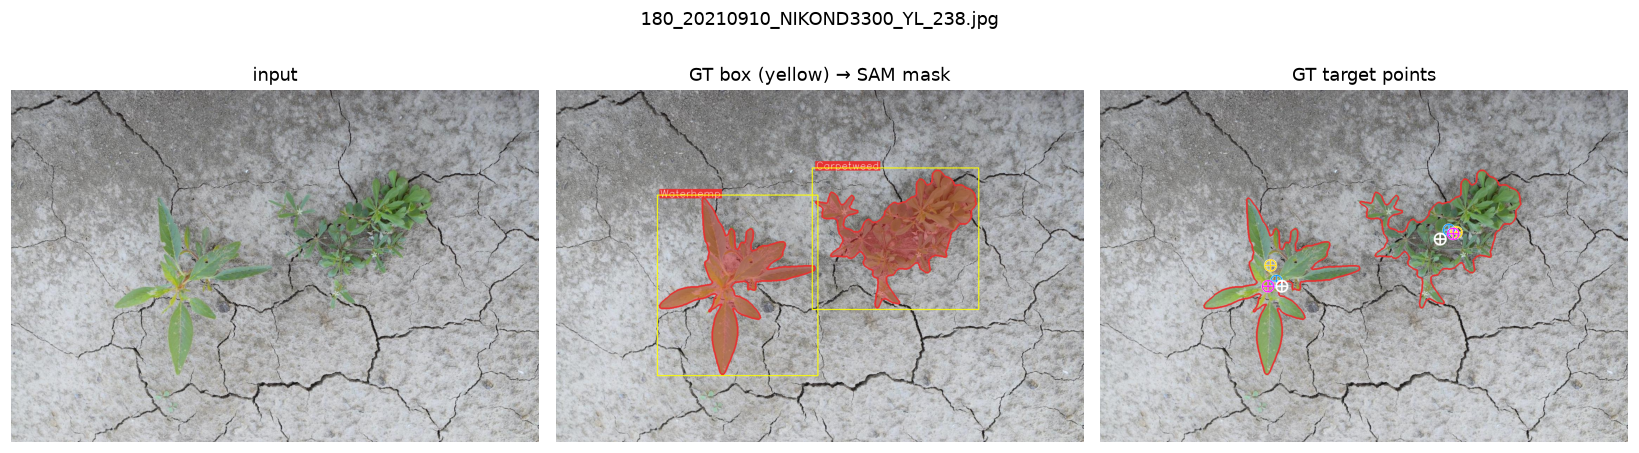

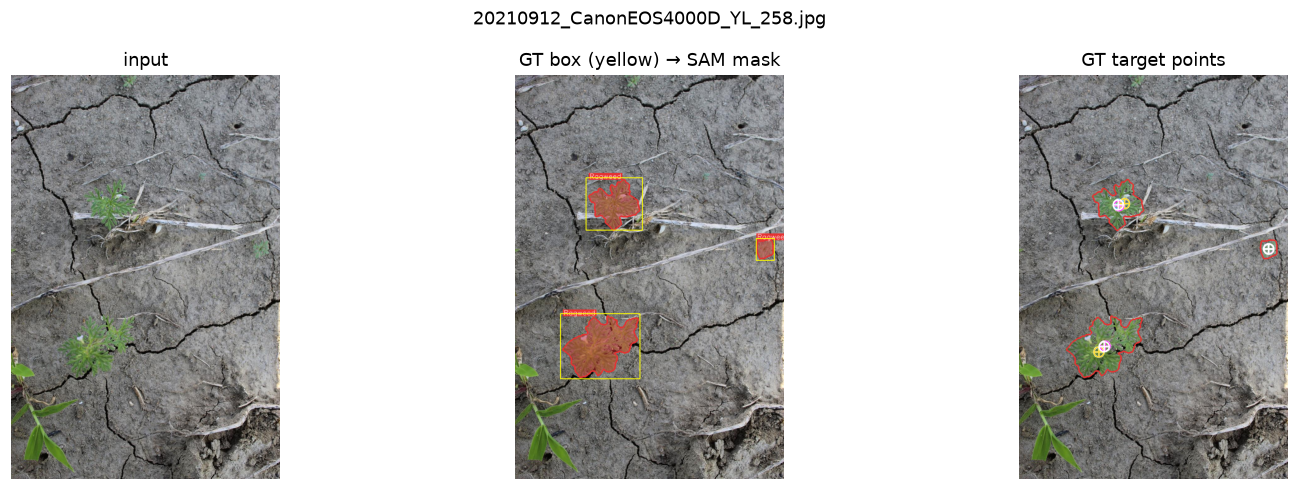

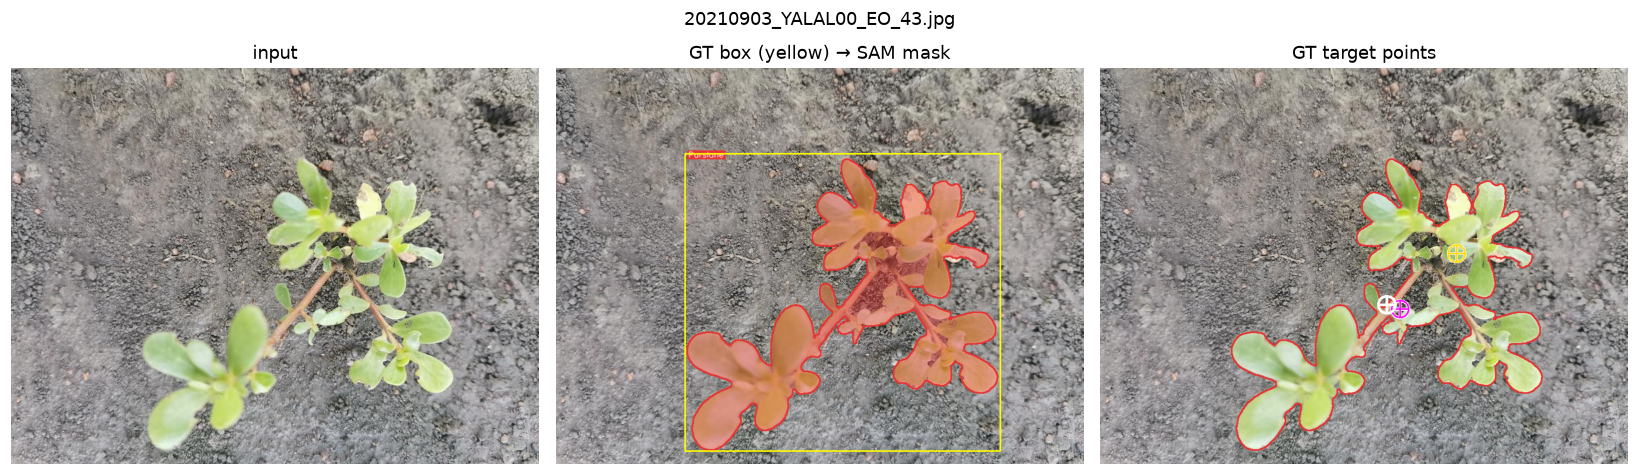

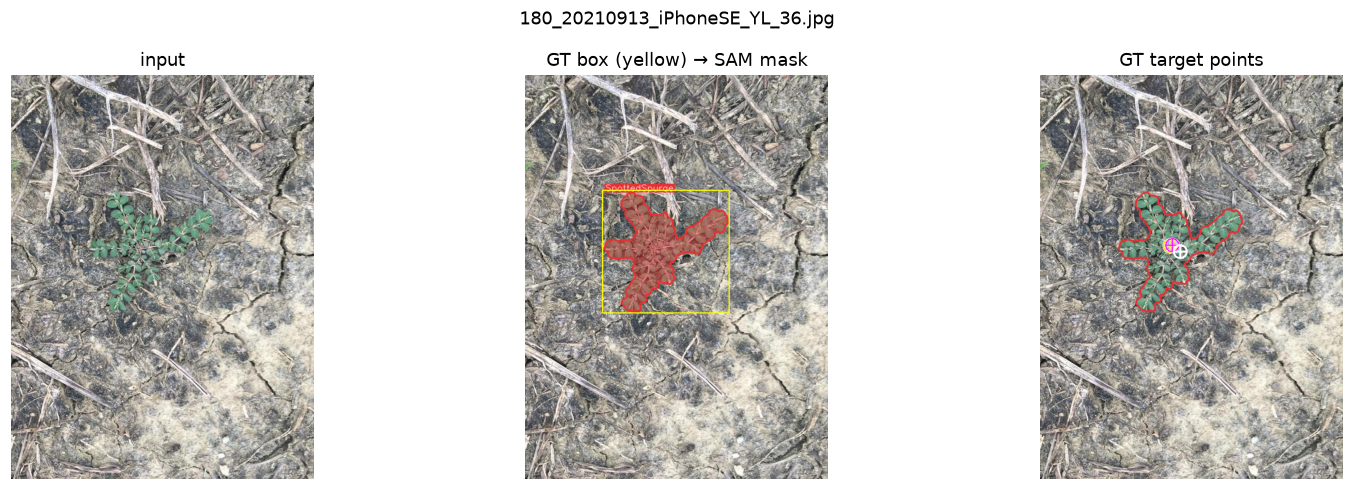

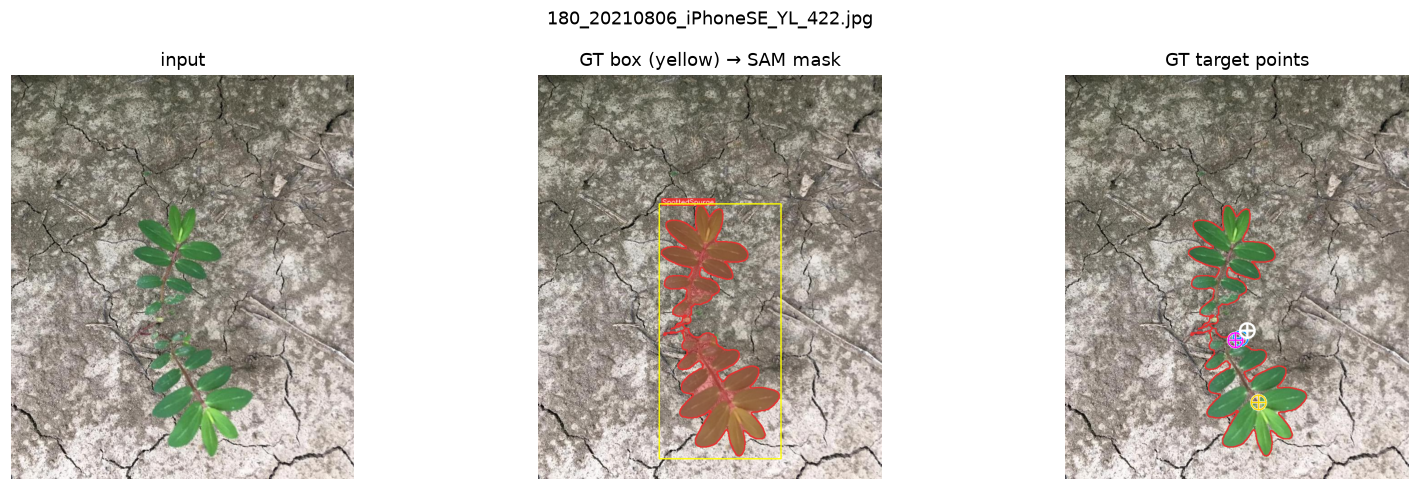

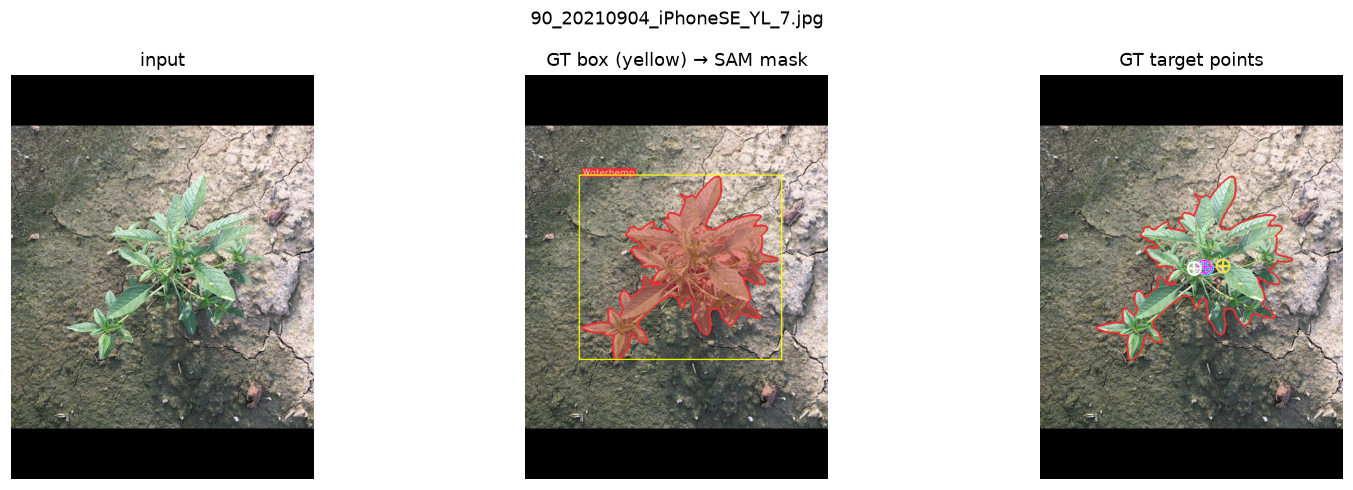

In [5]:
def show_ground_truth(image_path, split):
    image = load_rgb(image_path)
    h, w = image.shape[:2]
    instances = read_seg_labels(prepared_dir / "labels" / split / f"{image_path.stem}.txt")
    masks = [polygon_to_mask(inst.polygon, h, w) for inst in instances]
    labels = [class_names[inst.class_id] for inst in instances]

    boxes_panel = draw_instances(image, masks, labels=labels, color=GT_COLOR)
    for _, cx, cy, bw, bh in read_yolo_boxes(raw_dir / "labels" / f"{image_path.stem}.txt"):
        cv2.rectangle(boxes_panel, (int((cx - bw / 2) * w), int((cy - bh / 2) * h)),
                      (int((cx + bw / 2) * w), int((cy + bh / 2) * h)), (255, 255, 0), 2)

    points_panel = draw_instances(image, masks, color=GT_COLOR, fill=False)
    for method in POINT_METHODS:
        for mask in masks:
            point = target_point(mask, method)
            if point is not None:
                draw_target(points_panel, point, METHOD_COLORS[method])

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, panel, title in zip(axes, (image, boxes_panel, points_panel),
                                ("input", "GT box (yellow) → SAM mask", "GT target points")):
        ax.imshow(panel); ax.set_title(title); ax.axis("off")
    fig.suptitle(image_path.name); plt.tight_layout(); plt.show()


print("point colors:", {m: c for m, c in METHOD_COLORS.items()})
images = sorted((prepared_dir / "images" / SPLIT).glob("*"))
rng = np.random.default_rng(SEED)
for image_path in rng.choice(images, size=min(NUM_SAMPLES, len(images)), replace=False):
    show_ground_truth(image_path, SPLIT)

## Does each method's point land on its own weed?
Fraction of GT masks whose target point lies inside the mask. A point outside the mask would
fire the laser at soil or at a neighbouring crop, even with a perfect segmentation.

In [6]:
inside = {m: [] for m in POINT_METHODS}
for split in ("train", "val", "test"):
    for image_path in sorted((prepared_dir / "images" / split).glob("*")):
        h, w = cv2.imread(str(image_path)).shape[:2]
        for inst in read_seg_labels(prepared_dir / "labels" / split / f"{image_path.stem}.txt"):
            mask = polygon_to_mask(inst.polygon, h, w)
            for method in POINT_METHODS:
                inside[method].append(point_in_mask(target_point(mask, method), mask))
pd.Series({m: np.mean(v) for m, v in inside.items()}, name="point inside own GT mask").to_frame()

,point inside own GT mask
centroid,0.929690
distance_transform,1.000000
skeleton,1.000000
box_center,0.868204


## Images where SAM returned no mask
For these boxes the box rectangle itself was used as the GT mask (see `sam_fallbacks.txt`).

In [7]:
fallback_file = prepared_dir / "sam_fallbacks.txt"
fallbacks = fallback_file.read_text().splitlines() if fallback_file.exists() else []
print(len(fallbacks), "fallback boxes")
for line in fallbacks[:3]:
    split, stem = line.split()[0].split("/")
    show_ground_truth(next((prepared_dir / "images" / split).glob(f"{stem}.*")), split)

0 fallback boxes
